## Inspecting the hdf5 file structure
structure: 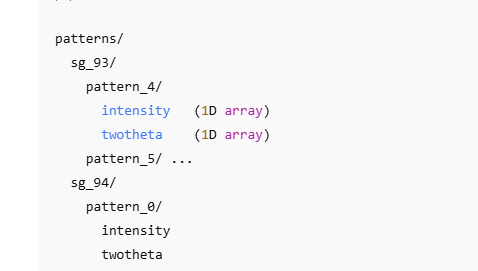



In [ ]:
import h5py

# Path to the HDF5 file
file_path = "2K_reflection.hdf5"

# Open and inspect the file
with h5py.File(file_path, "r") as f:
    def print_attrs(name, obj):
        print(f"🔍 Found: {name}")
        for key, val in obj.attrs.items():
            print(f"  - Attr: {key} = {val}")
    
    # Recursively walk through all groups and datasets
    f.visititems(print_attrs)


🔍 Found: data_split
🔍 Found: data_split/test_indices
🔍 Found: data_split/train_indices
🔍 Found: data_split/validation_indices
🔍 Found: ml_ready
🔍 Found: ml_ready/intensity
🔍 Found: ml_ready/masks
🔍 Found: ml_ready/space_groups
🔍 Found: ml_ready/twotheta
🔍 Found: patterns
🔍 Found: patterns/sg_1
🔍 Found: patterns/sg_1/pattern_0
  - Attr: space_group = 1
🔍 Found: patterns/sg_1/pattern_0/intensity
🔍 Found: patterns/sg_1/pattern_0/twotheta
🔍 Found: patterns/sg_1/pattern_1
  - Attr: space_group = 1
🔍 Found: patterns/sg_1/pattern_1/intensity
🔍 Found: patterns/sg_1/pattern_1/twotheta
🔍 Found: patterns/sg_1/pattern_2
  - Attr: space_group = 1
🔍 Found: patterns/sg_1/pattern_2/intensity
🔍 Found: patterns/sg_1/pattern_2/twotheta
🔍 Found: patterns/sg_1/pattern_3
  - Attr: space_group = 1
🔍 Found: patterns/sg_1/pattern_3/intensity
🔍 Found: patterns/sg_1/pattern_3/twotheta
🔍 Found: patterns/sg_1/pattern_4
  - Attr: space_group = 1
🔍 Found: patterns/sg_1/pattern_4/intensity
🔍 Found: patterns/sg_1/patt

## Loading Patterns into Patterns Table
So we need to walk patterns/sg_XX/pattern_NN/… and read each pair.
- creates Patterns3 (BLOB for intensities),
- stores the first twotheta once in PatternAxis(axis_id=1),
- checks all later twotheta arrays match (within tolerance) and warns if any differ,
- inserts every pattern with its SG inferred from the group name (or the group attr).


If twotheta grids differ per pattern, the script still inserts rows; it stores the first axis globally (PatternAxis) and logs a mismatch count. If we truly have multiple axes, we can extend the schema to an Axes table with a hash per axis and reference the right axis_id per row.

instrument/resolution/wavelength are filled with sensible defaults. If those are encoded as attributes anywhere (e.g., pat_grp.attrs[...]), we read them and set per-row values.

Run this as-is. It should populate Patterns3 from the nested layout and print counts so I can confirm it worked.

In [ ]:
import os, uuid, sqlite3, h5py, numpy as np, io

DB = os.path.abspath("crystal_xrd.db")
H5 = os.path.abspath("2K_reflection.hdf5")  # change as needed
BATCH_SIZE = 1000
AXIS_RTOL = 1e-6
AXIS_ATOL = 1e-8

def arr_to_blob(a: np.ndarray) -> bytes:
    '''each intensity array is serialized with NumPy’s .npy format and stuffed into a SQLite BLOB.
When you query it, you recover it with: np.load(io.BytesIO(blob), allow_pickle=False)'''
    buf = io.BytesIO()
    np.save(buf, np.asarray(a), allow_pickle=False)
    return buf.getvalue()

def ensure_schema(conn):
    cur = conn.cursor()
    cur.executescript("""
    CREATE TABLE IF NOT EXISTS PatternAxis (
      axis_id INTEGER PRIMARY KEY CHECK(axis_id=1),
      axis_type TEXT NOT NULL,
      two_theta BLOB NOT NULL
    );
    CREATE TABLE IF NOT EXISTS Patterns3 (
      pattern_id TEXT PRIMARY KEY,
      structure_id TEXT,
      space_group INTEGER,
      radiation_type TEXT,
      wavelength REAL,
      twotheta_min REAL, twotheta_max REAL, step_size REAL,
      resolution_u REAL, resolution_v REAL, resolution_w REAL,
      background_type TEXT,
      generator_method TEXT,
      generator_commit TEXT,
      normalization_type TEXT,
      axis_id INTEGER DEFAULT 1 REFERENCES PatternAxis(axis_id),
      intensity BLOB NOT NULL,
      comments TEXT,
      generation_timestamp TIMESTAMP DEFAULT CURRENT_TIMESTAMP
    );
    CREATE TABLE IF NOT EXISTS Reflections (
      reflection_id INTEGER PRIMARY KEY AUTOINCREMENT,
      pattern_id TEXT REFERENCES Patterns3(pattern_id),
      encoding TEXT NOT NULL,
      data BLOB NOT NULL
    );
    CREATE INDEX IF NOT EXISTS idx_patterns3_sg  ON Patterns3(space_group);
    CREATE INDEX IF NOT EXISTS idx_patterns3_rad ON Patterns3(radiation_type);
    """)
    conn.commit()

def load_h5_into_db(h5_path, db_path):
    print(f"DB: {db_path}\nH5: {h5_path}")
    conn = sqlite3.connect(db_path)
    ensure_schema(conn)
    cur = conn.cursor()

    inserted = 0
    axis_set = False
    axis_mismatch = 0

    with h5py.File(h5_path, "r") as f:
        if "patterns" not in f:
            raise RuntimeError("HDF5 missing top-level 'patterns' group.")

        # walk each space-group folder
        for sg_key in f["patterns"].keys():
            if not sg_key.startswith("sg_"):
                continue
            sg_grp = f["patterns"][sg_key]
            # space group from group name (fallback to attr if present)
            try:
                sg = int(sg_key.split("_")[1])
            except Exception:
                sg = int(sg_grp.attrs.get("space_group", -1))

            # iterate each pattern_N group
            batch = []
            for pat_key in sg_grp.keys():
                pat_grp = sg_grp[pat_key]
                if not isinstance(pat_grp, h5py.Group):
                    continue

                if "intensity" not in pat_grp or "twotheta" not in pat_grp:
                    # skip incomplete entries
                    continue

                y = pat_grp["intensity"][:]   # 1D intensities
                tth = pat_grp["twotheta"][:]  # 1D two-theta axis

                # store axis once; verify others match
                if not axis_set:
                    cur.execute(
                        "INSERT OR REPLACE INTO PatternAxis(axis_id, axis_type, two_theta) VALUES (1, ?, ?)",
                        ("two_theta", arr_to_blob(tth)),
                    )
                    axis_set = True
                    tmin, tmax = float(tth[0]), float(tth[-1])
                    step = float(np.round(tth[1]-tth[0], 8)) if len(tth) > 1 else None
                else:
                    # fetch stored axis to compare lazily just once
                    if inserted == 0:
                        cur.execute("SELECT two_theta FROM PatternAxis WHERE axis_id=1")
                        stored_tth = np.load(io.BytesIO(cur.fetchone()[0]), allow_pickle=False)
                    # compare
                    if not np.allclose(stored_tth, tth, rtol=AXIS_RTOL, atol=AXIS_ATOL):
                        axis_mismatch += 1
                        # still compute per-row meta from this tth
                        tmin, tmax = float(tth[0]), float(tth[-1])
                        step = float(np.round(tth[1]-tth[0], 8)) if len(tth) > 1 else None
                    else:
                        # use stored axis meta
                        tmin, tmax = float(stored_tth[0]), float(stored_tth[-1])
                        step = float(np.round(stored_tth[1]-stored_tth[0], 8)) if len(stored_tth) > 1 else None

                pid = str(uuid.uuid4())
                meta = (
                    pid,                      # pattern_id
                    None,                     # structure_id (unknown)
                    int(sg),                  # space_group
                    "X-ray",                  # radiation_type
                    1.54030,                  # wavelength (edit if known)
                    tmin, tmax, step,
                    0.025, 0.025, 0.025,      # resolution u,v,w (set true values if you have them)
                    "None",                   # background_type
                    "pyCrysfml",              # generator_method
                    "unknown",                # generator_commit
                    "max",                    # normalization_type (or 'none' if raw)
                    1,                        # axis_id (PatternAxis)
                    arr_to_blob(y),           # intensity blob
                    f"Imported from {os.path.basename(h5_path)} {sg_key}/{pat_key}",
                )
                batch.append(meta)

                if len(batch) >= BATCH_SIZE:
                    cur.executemany("""
                      INSERT INTO Patterns3(
                        pattern_id, structure_id, space_group, radiation_type, wavelength,
                        twotheta_min, twotheta_max, step_size,
                        resolution_u, resolution_v, resolution_w,
                        background_type, generator_method, generator_commit, normalization_type,
                        axis_id, intensity, comments
                      ) VALUES (?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?)
                    """, batch)
                    conn.commit()
                    inserted += len(batch)
                    print(f"Inserted {inserted} rows... (last {sg_key}/{pat_key})")
                    batch.clear()

            # flush any remainder for this sg
            if batch:
                cur.executemany("""
                  INSERT INTO Patterns3(
                    pattern_id, structure_id, space_group, radiation_type, wavelength,
                    twotheta_min, twotheta_max, step_size,
                    resolution_u, resolution_v, resolution_w,
                    background_type, generator_method, generator_commit, normalization_type,
                    axis_id, intensity, comments
                  ) VALUES (?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?)
                """, batch)
                conn.commit()
                inserted += len(batch)
                print(f"Inserted {inserted} rows... (final batch for {sg_key})")
                batch.clear()

    conn.close()
    print(f"✅ Done. Total inserted: {inserted}. Axis mismatches detected: {axis_mismatch}")

def verify(db_path):
    conn = sqlite3.connect(db_path)
    cur = conn.cursor()
    cur.execute("SELECT name FROM sqlite_master WHERE type='table' AND name LIKE 'Patterns%';")
    print("Tables:", [r[0] for r in cur.fetchall()])
    cur.execute("SELECT COUNT(*) FROM Patterns3;")
    print("Patterns3 row count:", cur.fetchone()[0])
    cur.execute("SELECT space_group, COUNT(*) FROM Patterns3 GROUP BY space_group ORDER BY space_group;")
    print("Per-SG counts:", cur.fetchall())
    conn.close()

if __name__ == "__main__":
    load_h5_into_db(H5, DB)
    verify(DB)



DB: /home/UserD/OrgA/crystal_database/crystal_xrd.db
H5: /home/UserD/OrgA/crystal_database/2K_reflection.hdf5
Inserted 8 rows... (final batch for sg_1)
Inserted 16 rows... (final batch for sg_10)
Inserted 24 rows... (final batch for sg_100)
Inserted 32 rows... (final batch for sg_101)
Inserted 40 rows... (final batch for sg_102)
Inserted 48 rows... (final batch for sg_103)
Inserted 56 rows... (final batch for sg_104)
Inserted 64 rows... (final batch for sg_105)
Inserted 72 rows... (final batch for sg_106)
Inserted 80 rows... (final batch for sg_107)
Inserted 88 rows... (final batch for sg_108)
Inserted 96 rows... (final batch for sg_109)
Inserted 104 rows... (final batch for sg_11)
Inserted 112 rows... (final batch for sg_110)
Inserted 120 rows... (final batch for sg_111)
Inserted 128 rows... (final batch for sg_112)
Inserted 136 rows... (final batch for sg_113)
Inserted 144 rows... (final batch for sg_114)
Inserted 152 rows... (final batch for sg_115)
Inserted 160 rows... (final batch

If you still don’t see Patterns3, run this quick check in Python (same working directory):

In [ ]:
import sqlite3, os
print(os.path.abspath("crystal_xrd.db"))
conn = sqlite3.connect("crystal_xrd.db")
cur = conn.cursor()
cur.execute("SELECT name FROM sqlite_master WHERE type='table';")
print(cur.fetchall())
conn.close()
